### imports & set up

In [1]:
import os
import sys
import json
import torch
import functools
import numpy as np
import pandas as pd
import gc
from typing import List
from torch import Tensor
from transformers import AutoTokenizer
from jaxtyping import Int
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import seaborn as sns
import scipy.stats as stats
from scipy.stats import mannwhitneyu, norm
import dotenv
import os
from pathlib import Path
import shutil
import traceback
from huggingface_hub.constants import HF_HUB_CACHE
from transformer_lens.model_bridge import TransformerBridge as TransformerBridge
from pathlib import Path
import plotly.io as pio
import plotly.express as px
import circuitsvis as cv

In [3]:
# Automatically reload modules when they change
%load_ext autoreload
%autoreload 2

In [4]:
print(torch.__version__) #should be 2.6 

2.6.0+cu124


In [5]:
# #load environment variables from .env file
# if not dotenv.load_dotenv():
#     print("Could not find dotenv file...")
# else:
#     print("Successfully loaded dotenv file. ", end="")
#     print(f"Environment PROJECT={os.environ.get('PROJECT')}")

#test

In [5]:
#set up paths
src_path = Path().resolve() / "../src"
sys.path.append(src_path)
project_root = src_path.resolve().parent  
sys.path.append(str(project_root))

In [6]:
#local imports from src 
import src.interp_toolkit as interp_toolkit

In [8]:
# known issue with statsmodels means there is an issue with the following package 
#https://github.com/statsmodels/statsmodels/issues/9584
# import statsmodels.api as sm
# from statsmodels.formula.api import ols

In [7]:
torch.set_grad_enabled(False)


In [8]:
interp_toolkit.load_environment_variables()

Successfully loaded dotenv file. Environment PROJECT=my_project


In [9]:
interp_toolkit.check_environment()

Hugging face cache inside the dockerfile lives at /home/aleshins/.cache
Hugging face token is hf_...Xso


### basic demo

##### load a model by name

In [10]:

#set its familty as a global variable -- this is only for purposes of prompt formatting
MODEL_FAMILY = "qwen" #options: "qwen", "llama", "mistral", "gemma"

#load a model 
model = interp_toolkit.load_model("Qwen/Qwen3.5-2B",device="cuda:1", model_family=MODEL_FAMILY)
    



Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

Moving model to device:  cuda
Model 'Qwen/Qwen3.5-2B' loaded successfully on cuda:1.


##### format a prompt using a chat template

In [13]:
#TODO: write function to read in stimuli and prompts from json files later--this is a simple demo for now
#suppose this might be constructed from a list of stimuli read in from a file.


sample_prompt= 'What is the capital city of France?'
system_message = "You are a helpful assistant."

#format a prompt for this stimulus item
this_prompt = interp_toolkit.create_prompt(MODEL_FAMILY, system_message, sample_prompt)
print(this_prompt)

<|im_start|>system
You are a helpful assistant..<|im_end|>
<|im_start|>user
What is the capital city of France?<|im_end|>
<|im_start|>assistant



In [18]:
#what dimensions should I expect? 
print('model dimensions are:',model.cfg.d_model)
print('vocabulary size is: ',model.cfg.d_vocab)

model dimensions are: 2048
vocabulary size is:  248320


##### call a model to generate a response

In [13]:
interp_toolkit.generate(model, this_prompt, max_new_tokens=50)

  0%|          | 0/50 [00:00<?, ?it/s]

100%|██████████| 50/50 [00:02<00:00, 17.45it/s]


['<|im_start|>system\nYou are a helpful assistant..<|im_end|>\n<|im_start|>user\nWhat is the capital city of France?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\nThe capital city of France is **Paris**. Located in the northern part of the country, it is situated on the banks of the Seine river and has been the political and cultural heart of the nation since the 12th century']

In [ ]:
#lists names of all the layers and transformer parts--for the curious 
interp_toolkit.return_model_parameters(model)

##### call a model and get activations and logits

In [21]:
#this returns all the activations for the last token in the prompt, for all layers, for all hook points that contain "resid_pre" in their name, as a dictionary.
# note, activation cache dimensions: n_layers, batch, num tokens, d_model)
activations, logits= interp_toolkit.get_activations(model, this_prompt,
                                                     token_pos  = -1, 
                                                     hook_type_filter="attn.hook_pattern")

In [22]:
#Notice the key structure. The layers are indicated by name. There could be multiple hook points for each layer. 
#This is not that easy to work with, so use filter_activation_cache() as show below to return a list of tensors for a specific hook point.
#which hookpoint you need is a matter of scientific relevance.
activations.keys()

dict_keys(['blocks.3.attn.hook_pattern', 'blocks.7.attn.hook_pattern', 'blocks.11.attn.hook_pattern', 'blocks.15.attn.hook_pattern', 'blocks.19.attn.hook_pattern', 'blocks.23.attn.hook_pattern'])

In [ ]:
activations_tensor = interp_toolkit.filter_activation_cache(activations, model=model,hook_name='linear_attn.hook_linear_attn_out')


Returning tensor with dimensions: 24 layers, 1 prompt batch(es), 1 token(s), 2048 model dimensions


torch.Size([24, 1, 1, 2048])

So, which part of the model do you want to look at? Not a straightforward question!

https://transformerlensorg.github.io/TransformerLens/content/model_structure.html
https://transformerlensorg.github.io/TransformerLens/content/hook_system.html  

This is determined by your question and interest. 

We provide a way to filter activations to return the ones you need with a simpler handle.



Relevant notes from documentation:
    * Internal attn head vectors: q, k, v, z. Shape [batch, pos, head_index, d_head].
    * Internal attn pattern style results: pattern (post softmax), attn_scores (pre-softmax). Shape
      [batch, head_index, query_pos, key_pos].
    * Attn head results: result. Shape [batch, pos, head_index, d_model].
    * Internal MLP vectors: pre, post, mid (only used for solu_ln - the part between activation +
      layernorm). Shape [batch, pos, d_mlp].
    * Residual stream vectors: resid_pre, resid_mid, resid_post, attn_out, mlp_out, embed,
      pos_embed, normalized (output of each LN or LNPre). Shape [batch, pos, d_model].
    * LayerNorm Scale: scale. Shape [batch, pos, 1].

#### visualize attention patterns

In [37]:
hook_name = "attn.hook_pattern"
activations, logits= interp_toolkit.get_activations(model, this_prompt,
                                                     token_pos  = -1, 
                                                     hook_type_filter=hook_name,
                                                     stop_at_layer = 4)


In [38]:
activations.keys()

dict_keys(['blocks.3.attn.hook_pattern'])

In [39]:

activations_tensor = interp_toolkit.filter_activation_cache(activations, model=model,layer=3,hook_name=hook_name)

Returning tensor with dimensions: 1 layers, 1 prompt batch(es), 8 token(s), 1 model dimensions


In [49]:
#from neel's notebook: another way to index from activation cache with shorthands. this is cool, need to understand it a bit better
attention_pattern=activations["pattern",3,"attn"]

In [59]:
attention_pattern

tensor([[[[2.9297e-02, 1.2573e-02, 7.6294e-03, 3.3379e-04, 2.0294e-03,
           1.3885e-03, 3.1250e-02, 4.0039e-02, 1.5259e-03, 1.7090e-03,
           1.3428e-02, 1.5450e-04, 1.1520e-03, 8.9111e-03, 2.9297e-02,
           3.2227e-02, 8.1177e-03, 5.8350e-02, 1.7969e-01, 3.6377e-02,
           1.3855e-02, 1.6309e-01, 1.7969e-01, 1.1572e-01, 2.3560e-02,
           1.6022e-03, 6.9580e-03]],

         [[1.0742e-01, 1.6479e-02, 6.9336e-02, 2.7313e-03, 2.9144e-03,
           3.7384e-03, 4.3640e-03, 4.0771e-02, 2.2461e-02, 2.9785e-02,
           1.1084e-01, 8.7891e-03, 5.0354e-03, 9.7656e-02, 2.9602e-03,
           2.4414e-03, 2.8687e-03, 1.4877e-03, 1.7929e-03, 7.9346e-04,
           3.0975e-03, 1.0986e-02, 2.9785e-02, 1.5137e-01, 2.3926e-02,
           1.1292e-02, 2.3438e-01]],

         [[1.0620e-02, 9.1797e-02, 2.8809e-02, 8.6975e-04, 4.6997e-03,
           5.3406e-03, 8.7891e-03, 7.8613e-02, 1.8677e-02, 4.3213e-02,
           1.7090e-01, 1.7624e-03, 1.4526e-02, 1.3379e-01, 6.8665e-03,
 

In [42]:
 tokens = model.to_tokens(this_prompt)

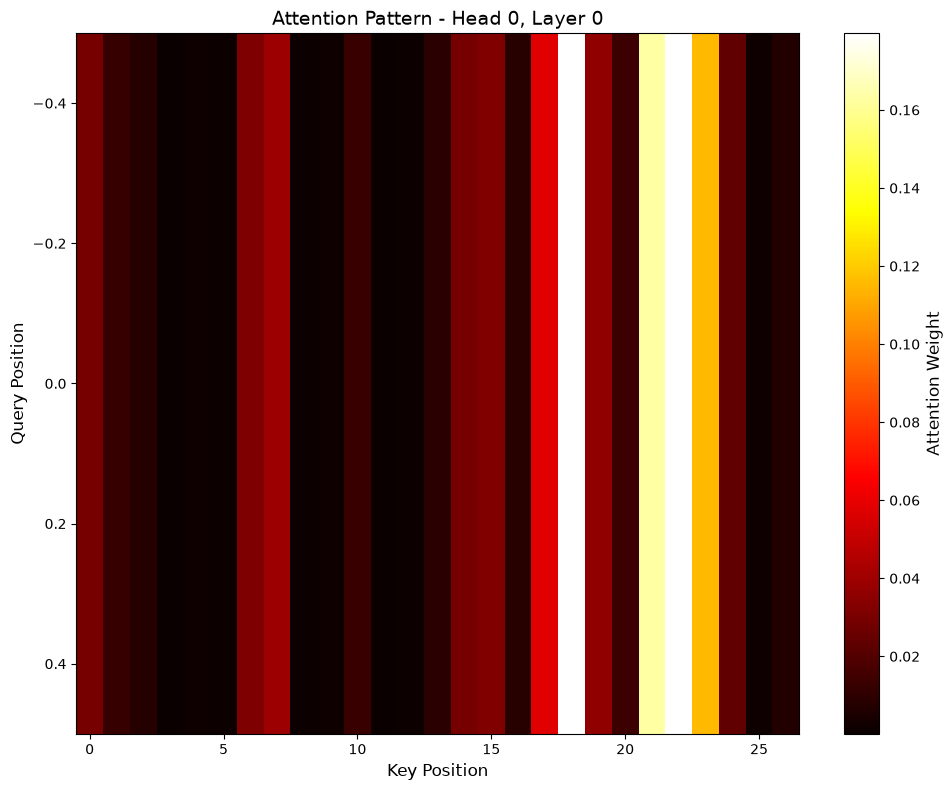

In [58]:
import matplotlib.pyplot as plt

attention_data = attention_pattern[0, 0].detach().float().cpu().numpy()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(attention_data, cmap='hot', aspect='auto')
ax.set_xlabel('Key Position', fontsize=12)
ax.set_ylabel('Query Position', fontsize=12)
ax.set_title('Attention Pattern - Head 0, Layer 0', fontsize=14)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Attention Weight', fontsize=12)
plt.tight_layout()
plt.show()

In [52]:
cv.attention.attention_heads(tokens=tokens, attention=attention_pattern)
from IPython.display import display
display(cv.attention.attention_heads(tokens=tokens, attention=attention_pattern))

#### generation with hooks

In [ ]:
log_probs = logits.log_softmax(dim=-1)
probs = logits.log_softmax(dim=-1)

next_token = logits[0, -1].argmax(dim=-1)
print(next_token)

next_tokens = torch.cat([tokens, torch.tensor(next_token, device='cuda', dtype=torch.int64)[None, None]], dim=-1)
new_logits = reference_gpt2(next_tokens)
print("New Input:", next_tokens)
print(next_tokens.shape)
print("New Input:", reference_gpt2.tokenizer.decode(next_tokens[0]))

print(new_logits.shape)
print(new_logits[-1, -1].argmax(-1))

print(reference_gpt2.tokenizer.decode(new_logits[-1, -1].argmax(-1)))


#### mean difference vectors and projections

In [16]:
#made up example of stim inputs
positive_stimuli = ["The capital of France is Paris.", "The language in France is French.", "French cuisine involves wonderful pastries."]
negative_stimuli = ["The capital of Germany is Berlin.", "The people of Germany speak German.", "A famous German composer is Bach."]
token_indices_positive = [(3,-1), (-3,-1), (-4,-1)]  # Example token indices for positive stimuli...just taking the last in each case
token_indices_negative = [(3,-1), (-3,-1), (-4,-1)]  # Example token indices for negative stimuli
hook_name = 'hook_resid_pre'
layer = None #if layer is None, you will get activations for all layers 
system_message = "You are a helpful assistant."

In [17]:
activation_vector = interp_toolkit.extract_activation_vector(model,
                                               model_family = interp_toolkit.MODEL_FAMILY, 
                                               positive_stimuli=positive_stimuli, 
                                               negative_stimuli=negative_stimuli,
                                               token_indices_positive=token_indices_positive, 
                                               token_indices_negative=token_indices_negative, 
                                               hook_name =hook_name,
                                               system_message=system_message)

(3, -1)
1
hook_resid_pre
Returning tensor with dimensions: 24 layers, 1 prompt batch(es), 22 token(s), 2048 model dimensions
Returning tensor with dimensions:  24 layers, 1 prompt batch(es), 2048 model dimensions
(-3, -1)
1
hook_resid_pre
Returning tensor with dimensions: 24 layers, 1 prompt batch(es), 2 token(s), 2048 model dimensions
Returning tensor with dimensions:  24 layers, 1 prompt batch(es), 2048 model dimensions
(-4, -1)
1
hook_resid_pre
Returning tensor with dimensions: 24 layers, 1 prompt batch(es), 3 token(s), 2048 model dimensions
Returning tensor with dimensions:  24 layers, 1 prompt batch(es), 2048 model dimensions
(3, -1)
1
hook_resid_pre
Returning tensor with dimensions: 24 layers, 1 prompt batch(es), 22 token(s), 2048 model dimensions
Returning tensor with dimensions:  24 layers, 1 prompt batch(es), 2048 model dimensions
(-3, -1)
1
hook_resid_pre
Returning tensor with dimensions: 24 layers, 1 prompt batch(es), 2 token(s), 2048 model dimensions
Returning tensor with d

In [109]:
activation_vector.shape

torch.Size([24, 2048])

In [27]:
#define stimuli to project onto the activation direction
stimuli = ["Bonjour!","Mais Ouis!", "Le Tour Eiffel","Shnitzel","Apfel", "Einstein"] 

#project all stimuli onto each layer's activation direction, in corresponding layers only!
projections = interp_toolkit.project_stimuli_onto_direction(stimuli= stimuli, 
                                                     model=model,
                                                    activation_direction=activation_vector,
                                                    hook_name='hook_resid_pre', 
                                                    token_ind=-1,
                                                    layer = None)

projections.shape

Returning tensor with dimensions: 24 layers, 6 prompt batch(es), 1 token(s), 2048 model dimensions
Returning projections with dimensions: 24 layers, 6 prompt batch(es)


(24, 6)

#### steering (directional addition, ablation, etc)